**Скопления галактик** - наиболее массивные гравитационно-связанные объекты во Вселенной

Вам предстоит работать в картах ACT+Planck и в этом обзоре были созданы крупнейшие каталоги скоплений галактик, найденные с помощью эффекта [Сюняеыва-Зельдовича](https://ru.wikipedia.org/wiki/Эффект_Сюняева_—_Зельдовича)

Масса скопления определяются относительно двух характеристик плотности: средней плотности вещества во Вселенной (m) или критической плотности Вселенной (crit или c, $\rho_{crit} = \frac{3H^2}{8\pi G}$). Для каждого из этих эталонов вводится значение плотностного контраста $\Delta$, указывающее, во сколько раз плотность в пределах заданного радиуса превышает выбранную опорную величину. Для численных симуляций наиболее часто используемым является $\Delta = 200$, который наиболее близок к вириальному радиусу скопления. В микроволновых и рентгеновских исследованиях, напротив, предпочтение обычно отдаётся контрасту $\Delta = 500$, поскольку соответствующий радиус охватывает область, где предположение о гидростатическом равновесии наиболее применимо. 

**Если будете брать массу, то индекс должен быть 500 и если есть m или c, то c**

Для оценки массы в СЗ используется интегральный Y-параметр, который получается путем интегрирования сигнала tSZ по объему скопления V:
$$Y = D_A^{-2}\frac{k_B \sigma_T}{m_e c^2} \int n_e T_e dV= D_A^{-2} \frac{\sigma_T}{m_e c^2} \int P_e dV$$
где $P_e$ - давление газа ($P_e = n_e k_B T_e$, $k_B$ - постоянная Больцмана, $T_e$ и $n_e$ - температура  и плотности числа электронов, $\sigma_T$ - сечение Томсона), $m_e c^2$ - масса покоя электрона, $D_A$ - угловое расстояние.

или максимальный у-параметр (как в коллаборации ACT):
$$y_0 = 10^{A_0} E(z)^2 \left(\frac{M_{500c}}{M_{pivot}}\right)^{1+B_0} Q(\theta_{500c})f_{rel}(M_{500c}, z)$$
где $E(z) = \sqrt{\Omega_m (1 + z)^3 + \Omega_\Lambda}$ - безразмерный параметр Хаббла, $10^{A_0}$ - нормировка, $B_0$, $M_{pivot}$ - константы, $Q(\theta_{500c})$ - функция несоотвествия фильтра, $f_{rel}$ - релятивисткие поправки (см. [статью](https://arxiv.org/abs/2009.11043))

А сам y/Y параметр получается из микроволновых карт на разных частотах с помощью многочастотной фильтрации и показывает, насколько скопление исказило чернотельный спектр реликтового фона. Это искажение меняет знак на частоте 217 ГГц: ослабляет излучение ниже этой частоты и усиливает выше.

**Важно, брать только значения масс с известными красными смещениями (z, redshift)** (z > 0)

In [4]:
%pip install astroquery

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 61.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 78.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [astroquery]2 [astroquery]

[notice] A new release of pip is available: 23.0.1 -> 25.2
[notice] To update, run: python3 -m pip install --upgrade pip


In [1]:
import load_catalogs as load
import pandas as pd, numpy as np
import os
import matplotlib.pyplot as plt 

# Основной каталог

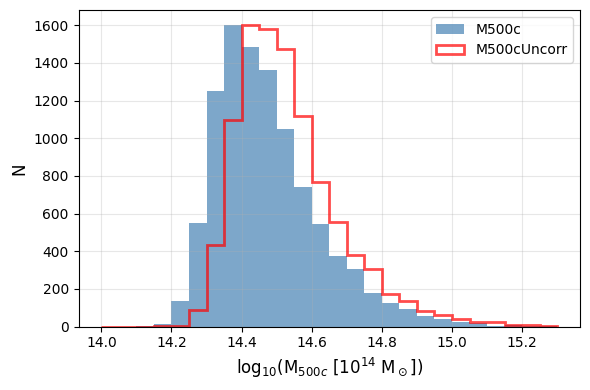

bins: [14.   14.05 14.1  14.15 14.2  14.25 14.3  14.35 14.4  14.45 14.5  14.55
 14.6  14.65 14.7  14.75 14.8  14.85 14.9  14.95 15.   15.05 15.1  15.15
 15.2  15.25 15.3 ]
counts_corr: [   0.    0.    2.   14.  136.  552. 1250. 1601. 1485. 1364. 1048.  741.
  543.  375.  306.  176.  128.   94.   55.   42.   25.   18.    5.    7.
    4.    2.]
counts_uncorr: [0.000e+00 0.000e+00 0.000e+00 1.000e+00 4.000e+00 8.800e+01 4.340e+02
 1.098e+03 1.599e+03 1.579e+03 1.472e+03 1.118e+03 7.690e+02 5.550e+02
 3.790e+02 3.040e+02 1.740e+02 1.360e+02 8.400e+01 6.200e+01 4.300e+01
 2.300e+01 2.600e+01 8.000e+00 7.000e+00 3.000e+00]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
import load_catalogs as load

actdr6 = ['ACTDR6']
output_folder = 'tables/'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

catal = load.download_catalogs(actdr6, base_path='./data processing/tables')

bins = np.arange(14, 15.3, 0.05)

plt.figure(figsize=(6, 4))

# ⬇️ Сохраняем результаты гистограмм
counts_corr, edges_corr, _ = plt.hist(
    np.log10(catal['ACTDR6'].M500c * 1e14),
    bins=bins,
    alpha=0.7,
    color='steelblue',
    edgecolor='none',
    linewidth=0.5,
    label='M500c'
)

counts_uncorr, edges_uncorr, _ = plt.hist(
    np.log10(catal['ACTDR6'].M500cUncorr * 1e14),
    bins=bins,
    alpha=0.7,
    color='red',
    histtype='step',
    linewidth=2,
    label='M500cUncorr'
)

plt.xlabel('log$_{10}$(M$_{500c}$ [$10^{14}$ M$_\odot$])', fontsize=12)
plt.ylabel('N', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# --- теперь у тебя есть массивы ---
print("bins:", bins)
print("counts_corr:", counts_corr)
print("counts_uncorr:", counts_uncorr)


In [2]:
actdr6 = ['ACTDR6']
output_folder= 'tables/'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)
catal = load.download_catalogs(actdr6, base_path='./data processing/tables')

Download complete.


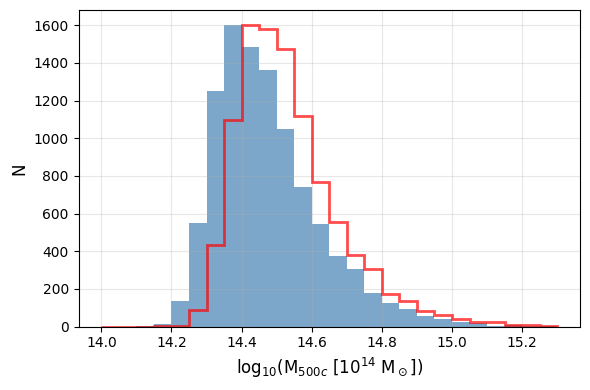

In [3]:
bins = np.arange(14, 15.3, 0.05)
plt.figure(figsize=(6, 4))
plt.hist(np.log10(catal['ACTDR6'].M500c*1e14), bins=bins, alpha=0.7, color='steelblue', edgecolor='none', linewidth=0.5)
plt.hist(np.log10(catal['ACTDR6'].M500cUncorr*1e14), bins=bins, alpha=0.7, color='red' ,histtype='step', linewidth=2)
plt.xlabel('log$_{10}$(M$_{500c}$ [$10^{14}$ M$_\odot$])', fontsize=12)
plt.ylabel('N', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

$M_{500c}$ массы лучше описывают сигнал с карт. Т.е. если вы просимулируете скопление с такой массой и вычтете профиль из карты, то остатка будешь меньше чем в случае вычитания $M_{500cUncorr}$ масс. Но последние лучше согласуются с измерениями масс, полученными в других миссиях

In [6]:
columns = ['name', 'RADeg', 'decDeg', 'redshift', 'redshiftType', 'M500c', 'M500cUncorr', 'theta500Arcmin']
df = catal['ACTDR6'][columns]
df.to_csv("clusters_selected.csv", index=False)


In [5]:
df.head()

,name,RADeg,decDeg,redshift,redshiftType,M500c,M500cUncorr
0,ACT-CL J0000.0+1002,0.002440,10.040771,0.671000,b'spec',3.324698,3.793656
1,ACT-CL J0000.0-3837,0.018316,-38.627492,0.292134,b'phot',2.477076,2.789617
2,ACT-CL J0000.1-5831,0.044460,-58.531160,0.546800,b'phot',2.412894,2.739957
3,ACT-CL J0000.2+1519,0.067571,15.330470,0.486800,b'phot',2.388019,2.778078
4,ACT-CL J0000.2-3936,0.074147,-39.602481,0.363598,b'phot',1.926320,2.207163


# Дополнительные каталоги

In [ ]:
dop = ['PSZ2', 'PSZ1', 'PSZ1_Barenna', 'PSZ-MCMF', 'ACTDR6', 'ACTDR5', 'PSZSPT', 'ComPRASS', 'ACT-MCMF', 'SPT-SZ', 
         'SPT2500D', 'SPTECS', 'SPTDEEP', 'SPTFAR', 'SPT100deg', 'SPT-MCMF']